In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import sys

# Project directory
PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))

print("Project:", PROJECT_ROOT)

# Find available dataset files
for path in sorted((PROJECT_ROOT / "data").rglob("*")):
    if path.is_file() and path.suffix.lower() in {".csv", ".xlsx", ".parquet"}:
        print(path.relative_to(PROJECT_ROOT))

Project: /ocean/projects/cis260266p/halhosan/PepGate
data/raw/CycPeptMPDB_Monomer_All.csv
data/raw/CycPeptMPDB_Peptide_All.csv
data/raw/monomer_table.csv


In [2]:
# Load CycPeptMPDB peptide-level dataset
data_path = PROJECT_ROOT / "data/raw/CycPeptMPDB_Peptide_All.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 3 records:")
display(df.head(3))

/tmp/ipykernel_3659586/3826509974.py:4: DtypeWarning: Columns (25: Detection_Limit_2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_path)


Dataset shape: (8466, 247)

Columns:
['ID', 'Source', 'Year', 'Version', 'Original_Name_in_Source_Literature', 'Structurally_Unique_ID', 'Same_Peptides_ID', 'Same_Peptides_Source', 'Same_Peptides_Permeability', 'Same_Peptides_Assay', 'SMILES', 'HELM', 'HELM_URL', 'Sequence', 'Sequence_LogP', 'Sequence_TPSA', 'Monomer_Length', 'Monomer_Length_in_Main_Chain', 'Molecule_Shape', 'Permeability', 'PAMPA', 'Caco2', 'MDCK', 'RRCK', 'Detection_Limit_1', 'Detection_Limit_2', 'R_PAMAP', 'R_Caco2', 'R_MDCK', 'R_RRCK', 'T_PAMPA', 'EPSA', 'PSA', '_3DPSA', 'NULL', 'MaxEStateIndex', 'MinEStateIndex', 'MaxAbsEStateIndex', 'MinAbsEStateIndex', 'qed', 'MolWt', 'HeavyAtomMolWt', 'ExactMolWt', 'NumValenceElectrons', 'NumRadicalElectrons', 'MaxPartialCharge', 'MinPartialCharge', 'MaxAbsPartialCharge', 'MinAbsPartialCharge', 'FpDensityMorgan1', 'FpDensityMorgan2', 'FpDensityMorgan3', 'BCUT2D_MWHI', 'BCUT2D_MWLOW', 'BCUT2D_CHGHI', 'BCUT2D_CHGLO', 'BCUT2D_LOGPHI', 'BCUT2D_LOGPLOW', 'BCUT2D_MRHI', 'BCUT2D_MRLOW

,ID,Source,Year,Version,Original_Name_in_Source_Literature,Structurally_Unique_ID,Same_Peptides_ID,Same_Peptides_Source,Same_Peptides_Permeability,Same_Peptides_Assay,...,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea,PC1,PC2,CHCl3_3DPSA,H2O_3DPSA
0,1,2006_Rezai_1,2006,1.0,Cyclosporine A,1,"[22, 932, 981, 1822, 1862, 2356, 7188, 7353]","['2011_White', '2015_Ahlbach', '2015_Bockus_1'...","[['-5.96'], ['-5.01'], ['-5.96'], ['-6.20'], [...","[['RRCK'], ['PAMPA'], ['RRCK'], ['PAMPA'], ['R...",...,0,0,0,0,0,0,-6.620416,-0.186784,174.0,173.0
1,2,2006_Rezai_1,2006,1.0,compound.1,2,[1048],['2015_Wang'],"[['-5.46', '-4.92']]","[['PAMPA', 'Caco2']]",...,0,0,0,0,0,0,2.443604,-1.286947,163.0,165.0
2,3,2006_Rezai_1,2006,1.0,compound.2,3,NaN,NaN,NaN,NaN,...,0,0,0,0,0,0,2.443604,-1.286947,163.0,162.0


In [3]:
# Inspect experimental PAMPA measurements
pampa = df.copy()
pampa["PAMPA_numeric"] = pd.to_numeric(
    pampa["PAMPA"], errors="coerce"
)

print("Total records:", len(df))
print("Numeric PAMPA labels:", pampa["PAMPA_numeric"].notna().sum())
print("Missing/non-numeric PAMPA labels:",
      pampa["PAMPA_numeric"].isna().sum())

print("\nPAMPA distribution:")
print(pampa["PAMPA_numeric"].describe())

print("\nTop 10 PAMPA sources:")
display(
    pampa.loc[pampa["PAMPA_numeric"].notna()]
    .groupby("Source")
    .agg(
        records=("ID", "size"),
        unique_structures=("Structurally_Unique_ID", "nunique"),
        median_pampa=("PAMPA_numeric", "median")
    )
    .sort_values("records", ascending=False)
    .head(10)
)

Total records: 8466
Numeric PAMPA labels: 7298
Missing/non-numeric PAMPA labels: 1168

PAMPA distribution:
count    7298.000000
mean       -5.907566
std         1.118836
min       -10.000000
25%        -6.260000
50%        -5.690000
75%        -5.250000
max        -3.900000
Name: PAMPA_numeric, dtype: float64

Top 10 PAMPA sources:


,records,unique_structures,median_pampa
Source,,,
2020_Townsend,3086,3086,-5.710000
2021_Kelly,1519,1518,-5.790000
2013_CHUGAI,878,878,-4.680000
2016_Furukawa,688,670,-5.775000
2024_Faris,234,234,-6.742525
2022_Bhardwaj,133,133,-5.820000
2018_Naylor,72,72,-5.635000
2015_Wang,62,62,-6.960000
2024_Koch,54,42,-6.389263


In [4]:
cols = [
    "Source",
    "PAMPA",
    "Detection_Limit_1",
    "Detection_Limit_2",
    "R_PAMAP"
]

# Inspect records at the lowest permeability values
display(
    df.loc[
        pampa["PAMPA_numeric"] <= -9,
        cols
    ].head(15)
)

print("\nRecords with PAMPA = -10:",
      (pampa["PAMPA_numeric"] == -10).sum())

print("\nDetection limit values:")
for col in ["Detection_Limit_1", "Detection_Limit_2", "R_PAMAP"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).head(10))

,Source,PAMPA,Detection_Limit_1,Detection_Limit_2,R_PAMAP
957,2015_Ahlbach,-10.0,< 10.14 (was undetected in the acceptor well o...,NaN,NaN
958,2015_Ahlbach,-10.0,< 10.14 (was undetected in the acceptor well o...,NaN,NaN
962,2015_Ahlbach,-9.4,NaN,NaN,NaN
964,2015_Ahlbach,-10.0,< 10.14 (was undetected in the acceptor well o...,NaN,NaN
1024,2015_Marelli,-10.0,permeability -10 is the value described in the...,NaN,NaN
1025,2015_Marelli,-10.0,permeability -10 is the value described in the...,NaN,NaN
1072,2015_Wang,-10.0,permeability values could not be determined du...,permeability values could not be determined du...,NaN
1073,2015_Wang,-10.0,permeability values could not be determined du...,permeability values could not be determined du...,NaN
1074,2015_Wang,-10.0,permeability values could not be determined du...,permeability values could not be determined du...,NaN
1089,2015_Wang,-10.0,permeability values could not be determined du...,< -6.85 (limit of detection issues prevented q...,NaN



Records with PAMPA = -10: 271

Detection limit values:

Detection_Limit_1
Detection_Limit_1
NaN                                                                                                                       8098
0 (x 10^-6 cm/s) is the value described in the original paper (permeability was set to -10 by CycPeptMPDB)                 249
Although it was not mentioned in the text, it may be -7 (by CycPeptMPDB)                                                    36
there was no value in original paper (since %T>100, permeability was set to -4 by CycPeptMPDB)                              15
< -7.0                                                                                                                       8
permeability values could not be determined due to poor sample solubility (permeability was set to -10 by CycPeptMPDB)       5
< -6.46                                                                                                                      4
< -6.5            

In [5]:
# Work only with records containing numeric PAMPA labels
labeled = pampa.loc[
    pampa["PAMPA_numeric"].notna()
].copy()

# Flag records with detection-limit annotations
labeled["has_detection_note"] = (
    labeled["Detection_Limit_1"].notna()
    | labeled["Detection_Limit_2"].notna()
)

# Identify the sentinel value separately
labeled["pampa_minus10"] = (
    labeled["PAMPA_numeric"] == -10
)

print("Total PAMPA-labeled records:", len(labeled))
print("PAMPA = -10:", labeled["pampa_minus10"].sum())
print("With detection-limit notes:", labeled["has_detection_note"].sum())

print("\nCross-tabulation:")
display(
    pd.crosstab(
        labeled["pampa_minus10"],
        labeled["has_detection_note"],
        margins=True
    )
)

print("\nRemaining without detection notes or -10:")
print(
    (
        ~labeled["has_detection_note"]
        & ~labeled["pampa_minus10"]
    ).sum()
)

Total PAMPA-labeled records: 7298
PAMPA = -10: 271
With detection-limit notes: 372

Cross-tabulation:


has_detection_note,False,True,All
pampa_minus10,,,
False,6925,102,7027
True,1,270,271
All,6926,372,7298



Remaining without detection notes or -10:
6925


In [6]:
# Initial clean regression dataset
model_df = labeled.loc[
    ~labeled["has_detection_note"]
    & ~labeled["pampa_minus10"]
].copy()

# Check repeated molecular structures
structure_counts = model_df.groupby(
    "Structurally_Unique_ID"
).agg(
    records=("ID", "size"),
    sources=("Source", "nunique"),
    min_pampa=("PAMPA_numeric", "min"),
    max_pampa=("PAMPA_numeric", "max")
)

duplicates = structure_counts[
    structure_counts["records"] > 1
].copy()

duplicates["pampa_range"] = (
    duplicates["max_pampa"] - duplicates["min_pampa"]
)

print("Clean PAMPA records:", len(model_df))
print("Unique structures:", model_df["Structurally_Unique_ID"].nunique())
print("Structures appearing multiple times:", len(duplicates))
print("Repeated across multiple sources:",
      (duplicates["sources"] > 1).sum())

print("\nLargest PAMPA disagreements:")
display(
    duplicates.sort_values(
        "pampa_range", ascending=False
    ).head(10)
)

Clean PAMPA records: 6925
Unique structures: 6863
Structures appearing multiple times: 49
Repeated across multiple sources: 18

Largest PAMPA disagreements:


,records,sources,min_pampa,max_pampa,pampa_range
Structurally_Unique_ID,,,,,
8403,2,1,-8.678860,-5.932987,2.745873
8425,2,1,-7.752086,-5.547768,2.204318
938,2,2,-7.400000,-5.220000,2.180000
25,7,7,-6.400000,-4.400000,2.000000
1122,2,2,-7.750000,-5.810000,1.940000
8404,2,1,-7.812399,-6.008307,1.804092
8426,2,1,-7.422041,-5.710382,1.711659
1,6,6,-6.600000,-5.010000,1.590000
935,2,2,-6.780000,-5.360000,1.420000


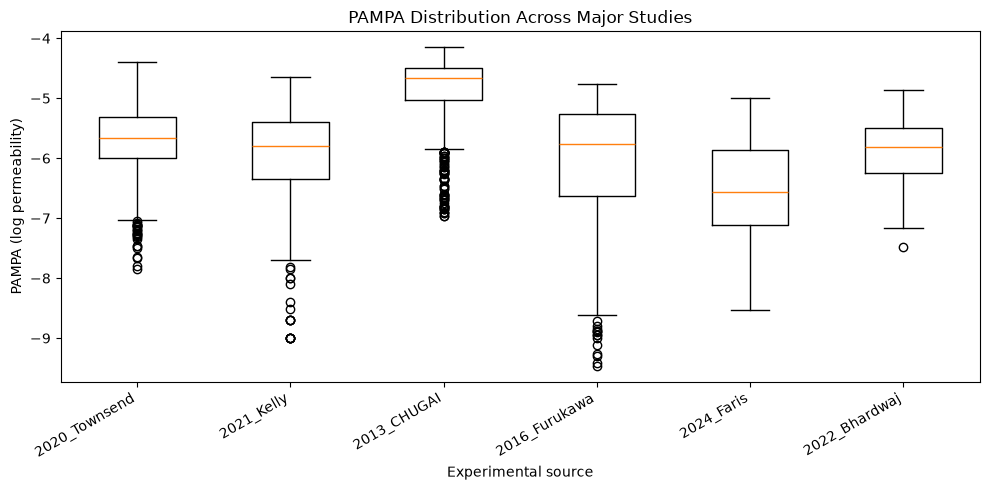

In [7]:
import matplotlib.pyplot as plt

# Select the six studies with the most clean PAMPA records
top_sources = model_df["Source"].value_counts().head(6).index

plot_df = model_df[
    model_df["Source"].isin(top_sources)
]

data = [
    plot_df.loc[
        plot_df["Source"] == source,
        "PAMPA_numeric"
    ].dropna()
    for source in top_sources
]

plt.figure(figsize=(10, 5))

plt.boxplot(data, tick_labels=top_sources)

plt.ylabel("PAMPA (log permeability)")
plt.xlabel("Experimental source")
plt.title("PAMPA Distribution Across Major Studies")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [8]:
from pathlib import Path

repo = PROJECT_ROOT / "external" / "PeptideCLM"

print("Official benchmark files:")
for path in sorted((repo / "clustered_data").rglob("*")):
    if path.is_file():
        print(path.relative_to(repo))

print("\nOfficial fine-tuning script:")
script = repo / "example_training_script.py"
print("Exists:", script.exists())

if script.exists():
    text = script.read_text()
    print("\nFirst 100 lines:\n")
    print("\n".join(text.splitlines()[:100]))

Official benchmark files:
clustered_data/all_clusters.csv

Official fine-tuning script:
Exists: True

First 100 lines:

import pandas as pd
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import Dataset
from tokenizer.my_tokenizers import SMILES_SPE_Tokenizer

# Load the data
data = pd.concat('clustered_data/all_clusters.csv')

train_df = data[data['cluster'] != 1]
test_df = data[data['cluster'] == 1]

# Print column names to ensure the correct name is used
print("Train dataset columns:", train_df.columns)
print("Test dataset columns:", test_df.columns)

# Convert pandas dataframes to Hugging Face datasets
train_dataset = Dataset.from_pandas(train_df)
test_dataset = Dataset.from_pandas(test_df)

# Load the tokenizer and model
model_name = 'aaronfeller/PeptideCLM-23M-all'  # Replace with your model of choice
tokenizer = SMILES_SPE_Tokenizer('tokenizer/new_vocab.txt', 'tokenizer/new_splits.txt')
model = AutoModelForSequ

In [9]:
benchmark_path = repo / "clustered_data" / "all_clusters.csv"
benchmark = pd.read_csv(benchmark_path, low_memory=False)

print("Benchmark shape:", benchmark.shape)
print("\nColumns:", benchmark.columns.tolist())

print("\nCluster distribution:")
print(benchmark["cluster"].value_counts(dropna=False).sort_index())

print("\nFirst 3 records:")
display(benchmark.head(3))

print("\nRelevant training-script lines:")
script_lines = script.read_text().splitlines()

keywords = [
    "train_df", "test_df", "label",
    "tokenizer", "from_pretrained",
    "TrainingArguments", "compute_metrics"
]

for i, line in enumerate(script_lines, start=1):
    if any(k in line for k in keywords):
        print(f"{i}: {line.strip()}")

Benchmark shape: (6701, 3)

Columns: ['SMILES', 'PAMPA', 'cluster']

Cluster distribution:
cluster
1    1546
2    1465
3    1455
4    1206
5     535
6     494
Name: count, dtype: int64

First 3 records:


,SMILES,PAMPA,cluster
0,CCCN1CC(=O)N(C)[C@@H](CC(C)C)C(=O)N(Cc2ccccc2)...,-5.13,1
1,CC(C)C[C@H]1C(=O)N[C@@H](Cc2ccccc2)C(=O)N2CCC[...,-5.63,1
2,CCCN1CC(=O)N[C@@H](CC(C)C)C(=O)N(Cc2ccccc2)CC(...,-5.75,1



Relevant training-script lines:
2: from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
4: from tokenizer.my_tokenizers import SMILES_SPE_Tokenizer
9: train_df = data[data['cluster'] != 1]
10: test_df = data[data['cluster'] == 1]
13: print("Train dataset columns:", train_df.columns)
14: print("Test dataset columns:", test_df.columns)
17: train_dataset = Dataset.from_pandas(train_df)
18: test_dataset = Dataset.from_pandas(test_df)
20: # Load the tokenizer and model
22: tokenizer = SMILES_SPE_Tokenizer('tokenizer/new_vocab.txt', 'tokenizer/new_splits.txt')
23: model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=1)
26: # Replace 'SMILES' with the actual name of the text column and 'PAMPA' with the label column in your CSV files
28: # Add the 'labels' field to the examples
29: examples['labels'] = examples['PAMPA']
30: tokenized_inputs = tokenizer(examples['SMILES'], padding='max_length', truncation=True, max_

In [10]:
# Compare molecular coverage between the official benchmark and CycPeptMPDB

official_smiles = set(benchmark["SMILES"].dropna())
clean_smiles = set(model_df["SMILES"].dropna())

print("Official benchmark molecules:", len(official_smiles))
print("Clean CycPeptMPDB molecules:", len(clean_smiles))

print("Shared SMILES:", len(official_smiles & clean_smiles))
print("Official-only SMILES:", len(official_smiles - clean_smiles))
print("Clean-data-only SMILES:", len(clean_smiles - official_smiles))

Official benchmark molecules: 6649
Clean CycPeptMPDB molecules: 6863
Shared SMILES: 6560
Official-only SMILES: 89
Clean-data-only SMILES: 303


In [11]:
# Check whether identical SMILES appear in different clusters
smiles_clusters = benchmark.groupby("SMILES")["cluster"].nunique()

cross_cluster = smiles_clusters[smiles_clusters > 1]

print("Unique SMILES:", benchmark["SMILES"].nunique())
print("SMILES appearing in multiple clusters:", len(cross_cluster))

# Check duplicates specifically across the planned test boundary
train = benchmark[benchmark["cluster"] != 1]
test = benchmark[benchmark["cluster"] == 1]

overlap = set(train["SMILES"]) & set(test["SMILES"])

print("Train records:", len(train))
print("Test records:", len(test))
print("Exact SMILES shared by train and test:", len(overlap))

Unique SMILES: 6649
SMILES appearing in multiple clusters: 0
Train records: 5155
Test records: 1546
Exact SMILES shared by train and test: 0


In [12]:
# Define the official cluster-held-out split
train_df = benchmark[benchmark["cluster"].isin([3, 4, 5, 6])].copy()
val_df   = benchmark[benchmark["cluster"] == 2].copy()
test_df  = benchmark[benchmark["cluster"] == 1].copy()

# Verify no exact-SMILES overlap
train_s = set(train_df["SMILES"])
val_s   = set(val_df["SMILES"])
test_s  = set(test_df["SMILES"])

assert not (train_s & val_s)
assert not (train_s & test_s)
assert not (val_s & test_s)

print(f"Train: {len(train_df):,}")
print(f"Validation: {len(val_df):,}")
print(f"Test: {len(test_df):,}")
print("No exact-SMILES overlap between splits.")

Train: 3,690
Validation: 1,465
Test: 1,546
No exact-SMILES overlap between splits.


In [13]:
# Save fixed splits for our first regression experiment
split_dir = PROJECT_ROOT / "data" / "processed" / "peptideclm_v1"
split_dir.mkdir(parents=True, exist_ok=True)

splits = {
    "train": train_df,
    "val": val_df,
    "test": test_df
}

for name, split in splits.items():
    output = split[["SMILES", "PAMPA", "cluster"]].copy()

    output["PAMPA"] = pd.to_numeric(
        output["PAMPA"], errors="raise"
    )

    output.to_csv(split_dir / f"{name}.csv", index=False)

    print(f"{name}: {len(output):,} records")

print("\nSaved to:", split_dir)

train: 3,690 records
val: 1,465 records
test: 1,546 records

Saved to: /ocean/projects/cis260266p/halhosan/PepGate/data/processed/peptideclm_v1


In [14]:
from external.PeptideCLM.tokenizer.my_tokenizers import SMILES_SPE_Tokenizer

tokenizer_dir = (
    PROJECT_ROOT / "external" / "PeptideCLM" / "tokenizer"
)

tokenizer = SMILES_SPE_Tokenizer(
    str(tokenizer_dir / "new_vocab.txt"),
    str(tokenizer_dir / "new_splits.txt")
)

def count_unknown(smiles):
    tokens = tokenizer.tokenize(smiles)

    # Our previously tested correction
    fixed = []
    for token in tokens:
        fixed.extend(["ccc", "c"] if token == "cccc" else [token])

    ids = tokenizer.convert_tokens_to_ids(fixed)
    return ids.count(tokenizer.unk_token_id)

for name, split in splits.items():
    unknown_counts = split["SMILES"].apply(count_unknown)

    print(
        f"{name}: "
        f"{(unknown_counts > 0).sum()} molecules with [UNK]"
    )

/ocean/projects/cis260266p/halhosan/envs/pepgate/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train: 7 molecules with [UNK]
val: 1 molecules with [UNK]
test: 0 molecules with [UNK]


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

results_dir = PROJECT_ROOT / "results" / "peptideclm_v1"

pred = pd.read_csv(results_dir / "test_predictions.csv")

print("Test records:", len(pred))

print("\nExperimental PAMPA:")
print(pred["PAMPA"].describe())

print("\nPredicted PAMPA:")
print(pred["prediction"].describe())

print("\nPrediction correlation:")
print(pred[["PAMPA", "prediction"]].corr())

NameError: name 'PROJECT_ROOT' is not defined

In [1]:
from pathlib import Path
import sys
import torch
import transformers

PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))

MODEL_ID = "aaronfeller/peptideclm-2-hybrid-small"

print("Project:", PROJECT_ROOT)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Model:", MODEL_ID)

/ocean/projects/cis260266p/halhosan/envs/pepgate/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project: /ocean/projects/cis260266p/halhosan/PepGate
PyTorch: 2.6.0+cu126
Transformers: 5.20.1
Model: aaronfeller/peptideclm-2-hybrid-small


In [2]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True
)

smiles = "NCC(=O)NCC(=O)O"

encoded = tokenizer(smiles, return_tensors="pt")

print("Token IDs:", encoded["input_ids"])
print("Token length:", encoded["input_ids"].shape[1])
print("Unknown tokens:",
      (encoded["input_ids"] == tokenizer.unk_token_id).sum().item())

[transformers] A new version of the following files was downloaded from https://huggingface.co/aaronfeller/peptideclm-2-hybrid-small:
- config.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


Token IDs: tensor([[  2, 364, 235, 364, 235, 150,   3]])
Token length: 7
Unknown tokens: 0


In [3]:
import pandas as pd

# Load the same benchmark used for PeptideCLM-1
benchmark = pd.read_csv(
    PROJECT_ROOT / "external/PeptideCLM/clustered_data/all_clusters.csv"
)

# Check tokenizer coverage on 100 real cyclic peptides
sample_smiles = benchmark["SMILES"].dropna().head(100)

encoded = tokenizer(
    sample_smiles.tolist(),
    truncation=False,
    padding=False
)

unk_id = tokenizer.unk_token_id

unknown_counts = [
    ids.count(unk_id) for ids in encoded["input_ids"]
]

lengths = [
    len(ids) for ids in encoded["input_ids"]
]

print("Molecules tested:", len(sample_smiles))
print("Molecules containing [UNK]:", sum(x > 0 for x in unknown_counts))
print("Maximum token length:", max(lengths))
print("Mean token length:", sum(lengths) / len(lengths))

Molecules tested: 100
Molecules containing [UNK]: 1
Maximum token length: 59
Mean token length: 42.91


In [4]:
for smiles, ids in zip(sample_smiles, encoded["input_ids"]):
    if unk_id in ids:
        print("SMILES:", smiles)
        print("Tokens:", tokenizer.convert_ids_to_tokens(ids))
        print("Unknown count:", ids.count(unk_id))

SMILES: CC(=O)N1CCC[C@H]1C(=O)N(C)[C@H](CC(C)C)C(=O)N[C@@H]1C(=O)N[C@H](Cc2ccccc2)C(=O)N[C@@H](CC(C)C)C(=O)N[C@H](Cc2cccc3ccccc23)C(=O)N(C)[C@H](C)C(=O)N[C@@H](CC(C)C)C(=O)N2CCC[C@H]2C(=O)O[C@@H]1C
Tokens: ['[CLS]', 'CC(=O)', 'N', '1', 'CCC', '[C@H]', '1', 'C(=O)N', '(C)', '[C@H]', '(C', 'C(C)C', ')', 'C(=O)N', '[C@@H]', '1', 'C(=O)N', '[C@H]', '(C', 'c', '2', 'ccccc', '2', ')', 'C(=O)N', '[C@@H]', '(C', 'C(C)C', ')', 'C(=O)N', '[C@H]', '(C', 'c', '2', 'cccc', '3', 'ccccc', '[UNK]', ')', 'C(=O)N', '(C)', '[C@H]', '(C)', 'C(=O)N', '[C@@H]', '(C', 'C(C)C', ')', 'C(=O)N', '2', 'CCC', '[C@H]', '2', 'C(=O)O', '[C@@H]', '1', 'C', '[SEP]']
Unknown count: 1


In [5]:
from transformers import AutoModel
import torch

model = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True
)

model.eval()

# Use a cyclic peptide that tokenized without [UNK]
valid_idx = next(
    i for i, ids in enumerate(encoded["input_ids"])
    if unk_id not in ids
)

smiles = sample_smiles.iloc[valid_idx]

inputs = tokenizer(smiles, return_tensors="pt")

with torch.no_grad():
    outputs = model(**inputs)

print("Model:", type(model).__name__)
print("Output type:", type(outputs).__name__)
print("Hidden-state shape:", outputs.last_hidden_state.shape)
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

[transformers] A new version of the following files was downloaded from https://huggingface.co/aaronfeller/peptideclm-2-hybrid-small:
- ChemPepMTR.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
Loading weights: 100%|██████████| 145/145 [00:00<00:00, 19310.79it/s]


Model: MLM_model
Output type: MLMOutput
Hidden-state shape: torch.Size([1, 39, 512])
Parameters: 31,668,629


In [6]:
regression_dir = (
    PROJECT_ROOT
    / "external/PeptideCLM-2"
    / "training/01_regression_benchmarks_training_code"
)

# Identify the official regression scripts
for path in sorted(regression_dir.rglob("*.py")):
    print(path.relative_to(PROJECT_ROOT))

external/PeptideCLM-2/training/01_regression_benchmarks_training_code/finetune_ensemble.py
external/PeptideCLM-2/training/01_regression_benchmarks_training_code/model/MTR_model.py


In [7]:
from pathlib import Path

regression_dir = (
    PROJECT_ROOT
    / "external/PeptideCLM-2"
    / "training/01_regression_benchmarks_training_code"
)

for filename in ["finetune_ensemble.py", "model/MTR_model.py"]:
    path = regression_dir / filename
    lines = path.read_text().splitlines()

    print(f"\n{'=' * 60}")
    print(f"FILE: {filename} ({len(lines)} lines)")
    print("=" * 60)

    keywords = [
        "class ", "def forward", "from_pretrained",
        "pool", "mean(", "[:, 0", "last_hidden_state",
        "nn.Linear", "freeze", "requires_grad",
        "loss", "optimizer", "train_test_split"
    ]

    for i, line in enumerate(lines, start=1):
        if any(keyword in line for keyword in keywords):
            start = max(0, i - 2)
            end = min(len(lines), i + 3)

            print(f"\n--- Lines {start + 1}–{end} ---")
            for j in range(start, end):
                print(f"{j + 1}: {lines[j]}")


FILE: finetune_ensemble.py (999 lines)

--- Lines 178–182 ---
178: 
179: def extract_mean_pool(outputs) -> torch.Tensor:
180:     if hasattr(outputs, "mean_pool"):
181:         return outputs.mean_pool
182:     if isinstance(outputs, dict) and "mean_pool" in outputs:

--- Lines 179–183 ---
179: def extract_mean_pool(outputs) -> torch.Tensor:
180:     if hasattr(outputs, "mean_pool"):
181:         return outputs.mean_pool
182:     if isinstance(outputs, dict) and "mean_pool" in outputs:
183:         return outputs["mean_pool"]

--- Lines 180–184 ---
180:     if hasattr(outputs, "mean_pool"):
181:         return outputs.mean_pool
182:     if isinstance(outputs, dict) and "mean_pool" in outputs:
183:         return outputs["mean_pool"]
184:     if hasattr(outputs, "pooler_output") and outputs.pooler_output is not None:

--- Lines 181–185 ---
181:         return outputs.mean_pool
182:     if isinstance(outputs, dict) and "mean_pool" in outputs:
183:         return outputs["mean_pool"]
184

In [8]:
# Inspect the pooled molecular representation
with torch.no_grad():
    outputs = model(**inputs)

print("Has mean_pool:", hasattr(outputs, "mean_pool"))

if hasattr(outputs, "mean_pool"):
    print("Mean-pool shape:", outputs.mean_pool.shape)
else:
    print("Available output fields:", outputs.keys())

Has mean_pool: True
Mean-pool shape: torch.Size([1, 512])


In [9]:
# Full benchmark tokenizer compatibility check
from collections import Counter

unknown_examples = []
max_length = 0

for split_name in ["train", "val", "test"]:
    split = pd.read_csv(
        PROJECT_ROOT / "data/processed/peptideclm_v1"
        / f"{split_name}.csv"
    )

    encoded_split = tokenizer(
        split["SMILES"].tolist(),
        truncation=False,
        padding=False
    )

    unknown_mask = [
        tokenizer.unk_token_id in ids
        for ids in encoded_split["input_ids"]
    ]

    lengths = [len(ids) for ids in encoded_split["input_ids"]]
    max_length = max(max_length, max(lengths))

    print(
        f"{split_name}: {sum(unknown_mask)} / {len(split)} "
        "molecules containing [UNK]"
    )

    unknown_examples.extend(
        s for s, has_unk in zip(split["SMILES"], unknown_mask)
        if has_unk
    )

print("Maximum token length:", max_length)
print("Total problematic records:", len(unknown_examples))


train: 41 / 3690 molecules containing [UNK]
val: 2 / 1465 molecules containing [UNK]
test: 7 / 1546 molecules containing [UNK]
Maximum token length: 101
Total problematic records: 50


In [10]:
from collections import Counter

# Identify unknown-token patterns across the benchmark
unknown_fragments = Counter()
problem_examples = []

for smiles in benchmark["SMILES"].dropna().unique():
    raw_tokens = tokenizer.tokenize(smiles)

    bad_tokens = [
        t for t in raw_tokens
        if tokenizer.convert_tokens_to_ids(t) == tokenizer.unk_token_id
    ]

    if bad_tokens:
        unknown_fragments.update(bad_tokens)
        problem_examples.append((smiles, bad_tokens))

print("Unknown token types:", len(unknown_fragments))
print("\nMost common unknown tokens:")

for token, count in unknown_fragments.most_common(20):
    print(repr(token), count)

print("\nFirst 5 problematic examples:")
for smiles, bad in problem_examples[:5]:
    print("\nUnknown:", bad)
    print("SMILES:", smiles)

Unknown token types: 1

Most common unknown tokens:
'[UNK]' 54

First 5 problematic examples:

Unknown: ['[UNK]']
SMILES: CC(=O)N1CCC[C@H]1C(=O)N(C)[C@H](CC(C)C)C(=O)N[C@@H]1C(=O)N[C@H](Cc2ccccc2)C(=O)N[C@@H](CC(C)C)C(=O)N[C@H](Cc2cccc3ccccc23)C(=O)N(C)[C@H](C)C(=O)N[C@@H](CC(C)C)C(=O)N2CCC[C@H]2C(=O)O[C@@H]1C

Unknown: ['[UNK]']
SMILES: CC(=O)N1CCC[C@H]1C(=O)N(C)[C@H](CC(C)C)C(=O)N[C@@H]1C(=O)N[C@H](Cc2ccc(F)c(F)c2)C(=O)N[C@@H](Cc2ccc(F)cc2)C(=O)N[C@H](Cc2cccc3ccccc23)C(=O)N(C)[C@H](C)C(=O)N[C@@H](CC(C)C)C(=O)N2CCC[C@H]2C(=O)O[C@@H]1C

Unknown: ['[UNK]']
SMILES: CC(=O)N1CCC[C@H]1C(=O)N(C)[C@H](CC(C)C)C(=O)N[C@@H]1C(=O)N[C@H](Cc2cccc3ccccc23)C(=O)N[C@@H](CCc2ccccc2)C(=O)N[C@H](CC(C)C)C(=O)N(C)[C@H](C)C(=O)N[C@@H](CC(C)C)C(=O)N2CCC[C@H]2C(=O)O[C@@H]1C

Unknown: ['[UNK]']
SMILES: CC(=O)N1CCC[C@H]1C(=O)N(C)[C@H](CC(C)C)C(=O)N[C@@H]1C(=O)N[C@H](Cc2ccccc2)C(=O)N[C@@H](Cc2ccc([N+](=O)[O-])cc2)C(=O)N[C@H](Cc2cccc3ccccc23)C(=O)N(C)[C@H](C)C(=O)N[C@@H](CC(C)C)C(=O)N2CCC[C@H]2C(=O)O[C@@H]1C

Unk

In [11]:
split_dir = PROJECT_ROOT / "data/processed/peptideclm_v1"
output_dir = PROJECT_ROOT / "data/processed/peptideclm2_v1"
output_dir.mkdir(parents=True, exist_ok=True)

for split_name in ["train", "val", "test"]:
    split = pd.read_csv(split_dir / f"{split_name}.csv")

    encoded = tokenizer(
        split["SMILES"].tolist(),
        truncation=False,
        padding=False
    )

    valid_mask = [
        tokenizer.unk_token_id not in ids
        for ids in encoded["input_ids"]
    ]

    compatible = split.loc[valid_mask].copy()
    compatible.to_csv(output_dir / f"{split_name}.csv", index=False)

    print(
        f"{split_name}: {len(compatible)} retained, "
        f"{len(split) - len(compatible)} excluded"
    )

train: 3649 retained, 41 excluded
val: 1463 retained, 2 excluded
test: 1539 retained, 7 excluded


In [3]:
from pathlib import Path
import sys
import torch
import transformers

PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))

/ocean/projects/cis260266p/halhosan/envs/pepgate/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr

v1 = pd.read_csv(
    PROJECT_ROOT / "results/peptideclm_v1/test_predictions.csv"
)

v2 = pd.read_csv(
    PROJECT_ROOT / "results/peptideclm2_v1/test_predictions.csv"
)

# Match records by SMILES and PAMPA, retaining a unique record key
# for any repeated measurements.
v1["replicate"] = v1.groupby(["SMILES", "PAMPA"]).cumcount()
v2["replicate"] = v2.groupby(["SMILES", "PAMPA"]).cumcount()

common = v1.merge(
    v2,
    on=["SMILES", "PAMPA", "replicate"],
    suffixes=("_clm1", "_clm2"),
    validate="one_to_one"
)

print("Common test records:", len(common))

y = common["PAMPA"].to_numpy()

for name, column in [
    ("PeptideCLM-1", "prediction_clm1"),
    ("PeptideCLM-2", "prediction_clm2")
]:
    pred = common[column].to_numpy()

    print(f"\n{name}")
    print("MAE:", round(mean_absolute_error(y, pred), 4))
    print("RMSE:", round(np.sqrt(mean_squared_error(y, pred)), 4))
    print("R2:", round(r2_score(y, pred), 4))
    print("Spearman:", round(spearmanr(y, pred).statistic, 4))

# Simple mean-prediction reference on the same test population
mean_baseline = np.full_like(y, y.mean())

print("\nTest-mean reference (diagnostic only)")
print("MAE:", round(mean_absolute_error(y, mean_baseline), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y, mean_baseline)), 4))

print("\nTarget mean:", round(y.mean(), 4))
print("CLM1 prediction mean:", round(common["prediction_clm1"].mean(), 4))
print("CLM2 prediction mean:", round(common["prediction_clm2"].mean(), 4))


Common test records: 1539

PeptideCLM-1
MAE: 0.5476
RMSE: 0.671
R2: -0.4635
Spearman: 0.2956

PeptideCLM-2
MAE: 0.5446
RMSE: 0.6689
R2: -0.4542
Spearman: 0.0964

Test-mean reference (diagnostic only)
MAE: 0.4088
RMSE: 0.5546

Target mean: -5.5681
CLM1 prediction mean: -5.9729
CLM2 prediction mean: -5.9387
